Brianna Aceves | DSC355 | 9.2 Exercise

In [1]:
#Import libraries for data preparation and neural network regression
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries imported successfully.")

Libraries imported successfully.


For Week 9, I am using Scikit-learn to create a neural network model using the same dataset and target variable from Week 3's exercise. I imported the libraries I needed to clean and prepare the data, train the neural network, and evaluate how well it predicts numerical values. This time, I will use a neural network instead of Linear Regression per this week's instructions. 

In [2]:
#Load the dataset
df = pd.read_csv("eda_data.csv")

#Display the first five rows
df.head()

,x0,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10,x11,x12,x13,y
0,-17.933519,6.559220,-14.452810,-4.732855,0.381673,2.563194,"($1,306.52)",-89.394348,-28.454044,-16.201298,-0.01%,0.217010,9.729891,-0.786431,0.666146
1,-37.214754,10.774930,-15.384004,-0.077339,10.983774,-15.210206,($24.86),153.032652,-32.557736,69.675903,0.00%,-3.584908,35.727926,-0.985552,0.378411
2,0.330441,-19.609972,-9.167911,2.064124,12.071688,12.506141,($110.85),-141.437276,-20.794952,55.042604,0.00%,-3.991366,-9.283523,-3.394718,0.624498
3,-13.709765,-8.011390,6.759264,1.727615,-1.768382,24.039733,($324.43),51.039653,-7.046908,-31.424419,0.01%,7.908897,-2.891882,-2.690222,0.126622
4,-4.202598,7.076210,-26.004919,-4.269696,-3.414224,2.115989,"$1,213.37",-31.046700,19.061182,-31.525515,-0.01%,0.846719,25.497480,3.516801,0.640025


I loaded the same dataset from Week 3 so I could use it again for this assignment. The goal is still to predict the numerical target variable, y, but this time I will use a neural network to see how well it can learn patterns in the data.

In [3]:
#Review dataset size and column types
print("Dataset Shape:", df.shape)

print("\nColumn Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (9999, 15)

Column Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9999 entries, 0 to 9998
Data columns (total 15 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x0      9996 non-null   float64
 1   x1      9995 non-null   float64
 2   x2      9996 non-null   float64
 3   x3      9997 non-null   float64
 4   x4      9997 non-null   float64
 5   x5      9999 non-null   float64
 6   x6      9996 non-null   object 
 7   x7      9998 non-null   float64
 8   x8      9999 non-null   float64
 9   x9      9996 non-null   float64
 10  x10     9997 non-null   object 
 11  x11     9995 non-null   float64
 12  x12     9999 non-null   float64
 13  x13     9998 non-null   float64
 14  y       9999 non-null   float64
dtypes: float64(13), object(2)
memory usage: 1.1+ MB

Missing Values:
x0     3
x1     4
x2     3
x3     2
x4     2
x5     0
x6     3
x7     1
x8     0
x9     3
x10    2
x11    4
x12    0
x13    1
y      0
dtype: int64

After reviewing the dataset, I confirmed that it contains 9,999 rows and 15 columns, including the target variable y. Most of the columns are already numerical, but x6 and x10 are stored as objects, so I'll need to convert those before training the neural network. I also noticed a few missing values across several columns, although none are missing from the target variable. Instead of removing those rows, I plan to handle the missing values during preprocessing so I can keep as much of the dataset as possible.

In [6]:
#Create a copy of the dataset
df_clean = df.copy()

#Convert currency values in x6 to numerical values
df_clean["x6"] = (
    df_clean["x6"]
    .astype("string")
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.replace("(", "-", regex=False)
    .str.replace(")", "", regex=False)
)

df_clean["x6"] = pd.to_numeric(
    df_clean["x6"], errors="coerce"
)

#Convert percentage values in x10 to numerical values
df_clean["x10"] = (
    df_clean["x10"]
    .astype("string")
    .str.replace("%", "", regex=False)
)

df_clean["x10"] = pd.to_numeric(
    df_clean["x10"], errors="coerce"
) / 100

#Review the cleaned columns
print(df_clean[["x6", "x10"]].head(10))

print("\nUpdated Data Types:")
print(df_clean[["x6", "x10"]].dtypes)

print("\nMissing Values After Conversion:")
print(df_clean[["x6", "x10"]].isnull().sum())

        x6     x10
0 -1306.52 -0.0001
1   -24.86     0.0
2  -110.85     0.0
3  -324.43  0.0001
4  1213.37 -0.0001
5 -1508.42     0.0
6 -1431.44  0.0001
7  1613.55  0.0001
8  1178.11     0.0
9  -312.04     0.0

Updated Data Types:
x6     Float64
x10    Float64
dtype: object

Missing Values After Conversion:
x6     3
x10    2
dtype: int64


Before preparing the neural network, I needed to clean up two columns that were stored as text instead of numbers. I started with creating a copy of the original dataset. Next I can see that column x6 contained currency values, while x10 contained percentages. I converted both into numerical values so the model could process them correctly. I also checked their data types and missing values after the conversion to make sure the data was ready for the next step.

In [7]:
#Separate predictors from the target variable
X = df_clean.drop(columns=["y"])
y = df_clean["y"]

#Review the predictor and target shapes
print("Predictor Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Summary:")
print(y.describe())

Predictor Shape: (9999, 14)
Target Shape: (9999,)

Target Summary:
count    9999.000000
mean        0.496744
std         0.288570
min         0.000193
25%         0.243486
50%         0.493514
75%         0.746923
max         0.999954
Name: y, dtype: float64


I separated the predictors from the target variable, y, which is what the neural network will be trying to predict. The dataset contains 9,999 rows with 14 predictor columns. Looking at the target summary, the average value of y is about 0.497, with values ranging from nearly 0 to 1. Since y is a continuous numerical variable, I'll be using a regression model rather than classification. Now that the predictors and target are separated, I can split the data into training and testing sets.

In [8]:
#Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

#Review the training and testing sizes
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target:", y_train.shape)
print("Testing Target:", y_test.shape)


Training Features: (7999, 14)
Testing Features: (2000, 14)

Training Target: (7999,)
Testing Target: (2000,)


I split the dataset into training and testing sets using an 80/20% split. This gave me 7,999 records for training and 2,000 records for testing, with 14 predictor columns in each set. I also used random_state=42 to make sure the split stays the same if I rerun the notebook. Now I can prepare the training data for the neural network and later use the testing data to see how well the model predicts new values.

In [9]:
#Create a preprocessing pipeline
preprocessing = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

#Fit preprocessing on training data
X_train_scaled = preprocessing.fit_transform(X_train)

#Apply the same preprocessing to testing data
X_test_scaled = preprocessing.transform(X_test)

#Review the prepared data
print("Training Data Shape:", X_train_scaled.shape)
print("Testing Data Shape:", X_test_scaled.shape)

print("\nMissing Values in Training Data:",
      np.isnan(X_train_scaled).sum())

print("Missing Values in Testing Data:",
      np.isnan(X_test_scaled).sum())

print("\nFirst Five Scaled Training Records:")
print(pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns
).head())

Training Data Shape: (7999, 14)
Testing Data Shape: (2000, 14)

Missing Values in Training Data: 0
Missing Values in Testing Data: 0

First Five Scaled Training Records:
         x0        x1        x2        x3        x4        x5        x6  \
0 -0.814077 -0.742488  1.222002 -0.579013 -0.280803  0.314056  0.121598   
1 -1.022163  1.360762  0.708045 -0.639316 -1.087730 -0.529193  1.196566   
2  0.719991 -0.119109  0.563344  0.193510  1.084990  1.724939 -0.515195   
3 -0.411518 -1.327507 -0.952571  0.535138 -0.149742 -1.739171 -1.100816   
4 -1.119124 -1.528252 -0.017023 -2.160888  0.186048 -1.010461  0.501336   

         x7        x8        x9       x10       x11       x12       x13  
0 -0.517220  0.279395  1.184212  0.002624 -0.867874 -1.287547 -1.617509  
1  0.251786 -0.551334 -0.669197  0.956681  0.509439  1.076099 -0.560088  
2 -1.412814 -0.345398 -0.513411 -1.905490  0.734658 -0.589417 -1.267589  
3  2.030625  0.175523  2.356994  0.956681 -1.765497 -0.457828 -0.068595  
4  0.7020

After splitting the dataset, I handled the missing values by replacing them with the median of each predictor column. I also used StandardScaler to standardize the numerical features so they're on a similar scale. After checking the results, both the training and testing datasets have zero missing values, and the number of records stayed the same. I also made sure the preprocessing was fitted only on the training data to avoid using information from the testing data. Now the data should be ready to train the neural network.

In [13]:
#Create a neural network regression model
nn_model = MLPRegressor(
    max_iter=500,
    random_state=42,
    early_stopping=True
)

#Train the neural network
nn_model.fit(X_train_scaled, y_train)

#Confirm it's trained
print("Neural network training completed!")
print("Training Iterations:", nn_model.n_iter_)

Neural network training completed!
Training Iterations: 23


For this step, I used Scikit-learn's MLPRegressor to create a neural network for predicting numerical values. I set the maximum number of training iterations to 500 and included early stopping so the model could stop when it was no longer improving enough. Looking at the output, the model completed 23 iterations instead of the full 500. I also used random_state=42 to keep my results consistent. Now that the model has finished training, I can use the testing data to see how well it makes predictions.

In [18]:
#Use the neural network to predict values
y_pred = nn_model.predict(X_test_scaled)

#Compare actual and predicted values
predictions_df = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

#Display the first 10 predictions
print("Actual vs. Predicted Values:")
print(predictions_df.head(10))

Actual vs. Predicted Values:
     Actual  Predicted
0  0.562558   0.465820
1  0.842013   0.470946
2  0.835992   0.394431
3  0.231668   0.642368
4  0.382307   0.383569
5  0.568551   0.492629
6  0.796037   0.746755
7  0.784381   0.465769
8  0.913742   0.419588
9  0.565069   0.409015


After training the neural network, I used the testing data to generate predictions for y. I compared the first 10 predicted values with the actual values to get an idea of how the model was performing. Looking at the results, some predictions were pretty close, while others were noticeably different. For example, one actual value was about 0.38, and the model predicted almost the same value. However, another actual value was around 0.84, and the prediction was closer to 0.47. This shows that the model is making predictions, but I still need to evaluate how accurate they are overall.

In [15]:
#Evaluate the neural network predictions
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

#Display the evaluation results
print("Neural Network Evaluation Results:")
print("Mean Absolute Error (MAE):", round(mae, 4))
print("Root Mean Squared Error (RMSE):", round(rmse, 4))
print("R-squared (R2):", round(r2, 4))

Neural Network Evaluation Results:
Mean Absolute Error (MAE): 0.2586
Root Mean Squared Error (RMSE): 0.3016
R-squared (R2): -0.0878


After generating the predictions, I evaluated the neural network using MAE, RMSE, and R2. The MAE was 0.2586, meaning the predictions were off by about 0.26 on average, while the RMSE was slightly higher at 0.3016. What stood out to me was the negative R2 score of -0.0878. From what I understand, this means the neural network performed worse than simply predicting the average value of y. Although the model was able to generate predictions, these results show that it wasn't very accurate on the testing data. I think this is a good example of why evaluating a model is important instead of assuming it works well just because it produces predictions.

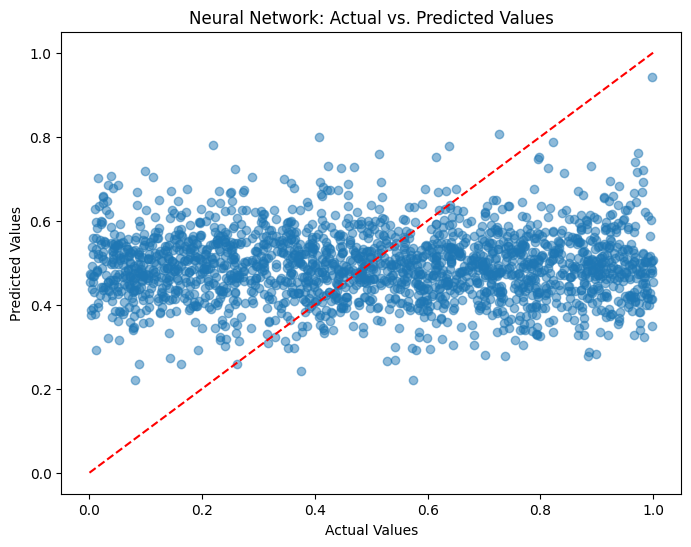

In [16]:
#Visuals
#Plot actual vs. predicted values
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.5)

#Add a reference line for perfect predictions
plt.plot([0, 1], [0, 1], "r--")

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Neural Network: Actual vs. Predicted Values")

plt.show()

I created a scatterplot to compare the actual values with the neural network's predictions. The red dashed line represents where the predictions would fall if they were completely accurate. Looking at the graph, I noticed that most of the predictions are grouped around 0.4 to 0.6, even though the actual values range from almost 0 to 1. A lot of the points are also pretty far from the red line, which helps explain the negative R2 score from the previous step. It looks like the model is predicting values closer to the average rather than finding strong patterns in the dataset.

In [17]:
#Create baseline predictions using the training target average
baseline_pred = np.full(
    len(y_test),
    y_train.mean()
)

#Calculate baseline performance
baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_pred))
baseline_r2 = r2_score(y_test, baseline_pred)

#Compare baseline and neural network results
comparison = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2"],
    "Neural Network": [mae, rmse, r2],
    "Baseline": [baseline_mae, baseline_rmse, baseline_r2]
})

print("Model Performance Comparison:")
print(comparison.round(4))

Model Performance Comparison:
  Metric  Neural Network  Baseline
0    MAE          0.2586    0.2506
1   RMSE          0.3016    0.2893
2     R2         -0.0878   -0.0010


For this step, I compared my neural network with a simple baseline model that predicts the average value of y. I wanted to see whether using a neural network actually improved the predictions. Looking at the results, the baseline performed slightly better, with an MAE of 0.2506 compared to the neural network's 0.2586. The baseline also had a lower RMSE and a better R2 score. I thought this was interesting because I expected the neural network to perform better than just predicting an average. This comparison helped me understand that using a more complicated model doesn't necessarily mean it will give better results.

For this week's assignment, I used the same dataset and target variable from Week 3 to create a neural network regression model using Scikit-learn. I started by reviewing and cleaning the data, separating the predictors from the target variable, and splitting the dataset into training and testing sets. I also handled missing values and scaled the predictors before training the model. After training the neural network, I used it to predict numerical values and evaluated the results using MAE, RMSE, and R2. Although the model was able to make predictions, its R2 score was negative, which showed that it wasn't performing very well. The scatterplot also showed that most predictions were grouped near the average instead of following the actual values. I also compared the neural network with a simple baseline model and found that the baseline performed slightly better. Overall, this exercise helped me better understand how neural networks can be used for regression and why it's important to evaluate a model instead of assuming it works well just because it produces predictions.